<a href="https://colab.research.google.com/github/atharvdhobale/Ml-Projects/blob/main/non_linaear_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


Dataset shape: (500, 2)
Target shape: (500,)


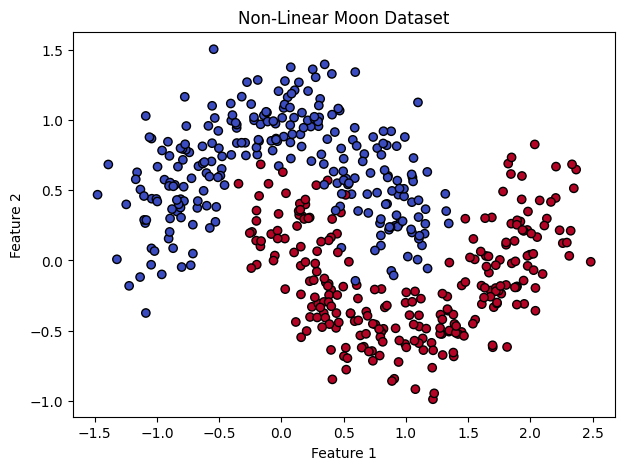

In [ ]:
X, y = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.title("Non-Linear Moon Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 400
Testing samples: 100


In [ ]:
models = {
    "Polynomial SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly", degree=3, C=1.0))
    ]),

    "RBF SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Polynomial SVM trained successfully!
RBF SVM trained successfully!


In [ ]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print(f"Accuracy: {accuracy * 100:.2f}%")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

display(pd.DataFrame(results))


Polynomial SVM
Accuracy: 85.00%

Confusion Matrix:
[[43  7]
 [ 8 42]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85        50
           1       0.86      0.84      0.85        50

    accuracy                           0.85       100
   macro avg       0.85      0.85      0.85       100
weighted avg       0.85      0.85      0.85       100


RBF SVM
Accuracy: 99.00%

Confusion Matrix:
[[50  0]
 [ 1 49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        50
           1       1.00      0.98      0.99        50

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



,Model,Accuracy (%)
0,Polynomial SVM,85.0
1,RBF SVM,99.0


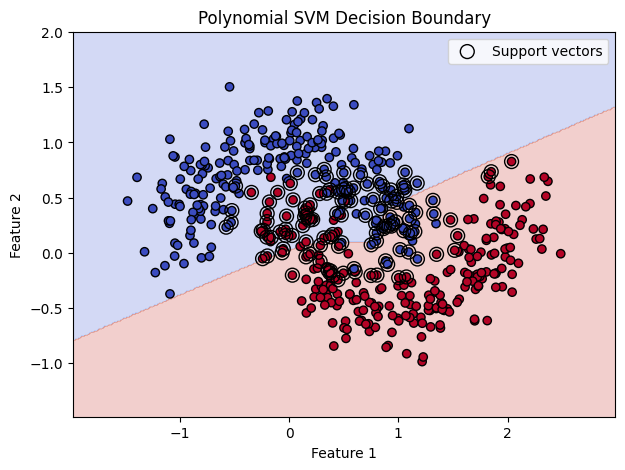

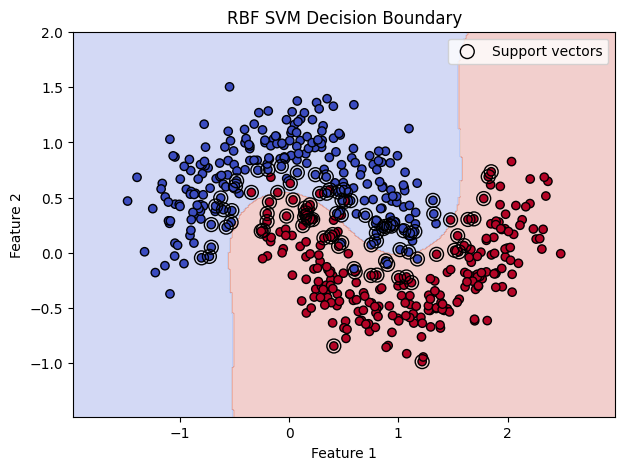

In [ ]:
def plot_decision_boundary(model, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="k"
    )

    svm = model.named_steps["svm"]
    scaler = model.named_steps["scaler"]

    support_vectors_original = scaler.inverse_transform(
        svm.support_vectors_
    )

    plt.scatter(
        support_vectors_original[:, 0],
        support_vectors_original[:, 1],
        s=100,
        facecolors="none",
        edgecolors="black",
        label="Support vectors"
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.show()


for name, model in models.items():
    plot_decision_boundary(model, name + " Decision Boundary")

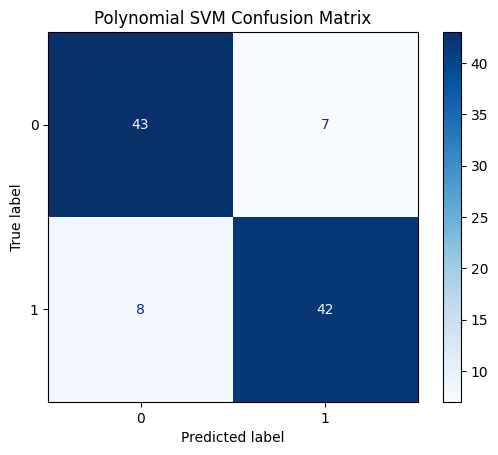

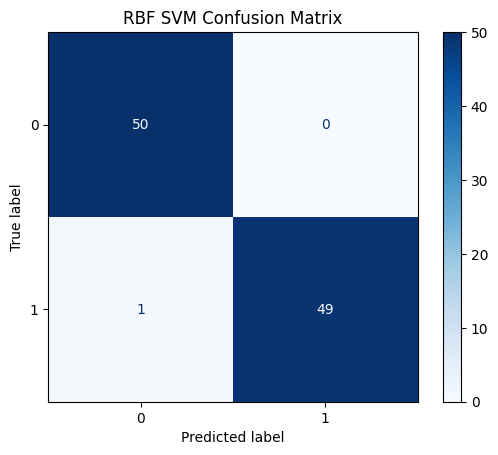

In [ ]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        cmap="Blues"
    )

    plt.title(name + " Confusion Matrix")
    plt.show()